In [12]:
# installation des modules
%pip install matplotlib scipy numpy scikit-learn
import numpy as np
import matplotlib.pyplot as plt
import scipy
import utils
from sklearn.decomposition import NMF

Note: you may need to restart the kernel to use updated packages.


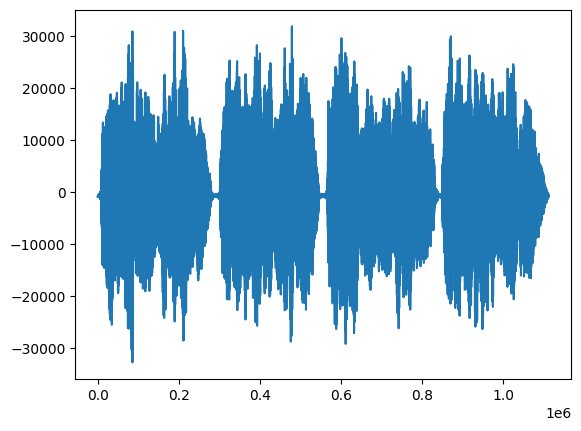

In [3]:
# Chargement du fichier audio
fs, x = scipy.io.wavfile.read("son/01-AchGottundHerr.wav")
T = len(x) / fs  #duree totale du signal
x = x.astype(float)
plt.plot(x)

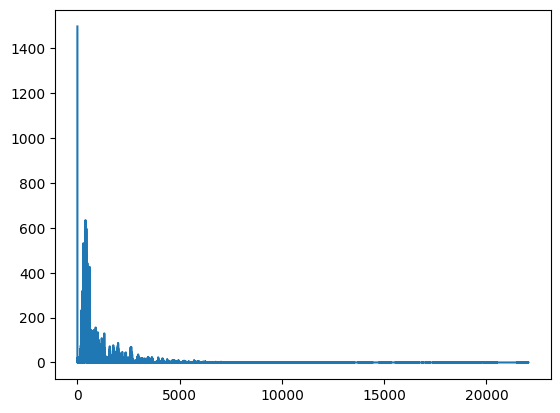

In [4]:
# Application de la transformée de Fourier real general
X = np.fft.rfft(x)
freqs = np.fft.rfftfreq(len(x), 1/fs)
plt.plot(freqs, np.abs(X)*2/len(x))

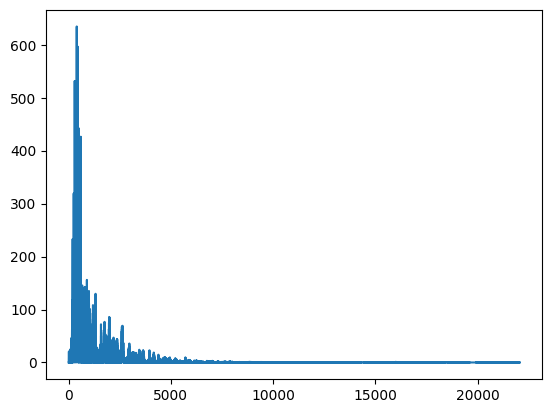

In [5]:
# Filtrer le bruit via un filtre passe haut pour eliminer la composante continue
fc = 10 # hz par exemple
x_filtre = utils.filtre_passe_haut(x, fc, 1/fs)
X_filtre = np.fft.rfft(x_filtre)
freqs_filtre = np.fft.rfftfreq(len(x_filtre), 1/fs)
plt.plot(freqs_filtre, np.abs(X_filtre)*2/len(x_filtre))

In [6]:
# Teste signal reconstruit
x_inv = np.fft.irfft(X_filtre, n=len(x))

# normaliser si nécessaire
x_inv_norm = x_inv / np.max(np.abs(x_inv))  
x_inv_int16 = (x_inv_norm * 32767).astype(np.int16)

scipy.io.wavfile.write("son_filtre.wav", fs, x_inv_int16)

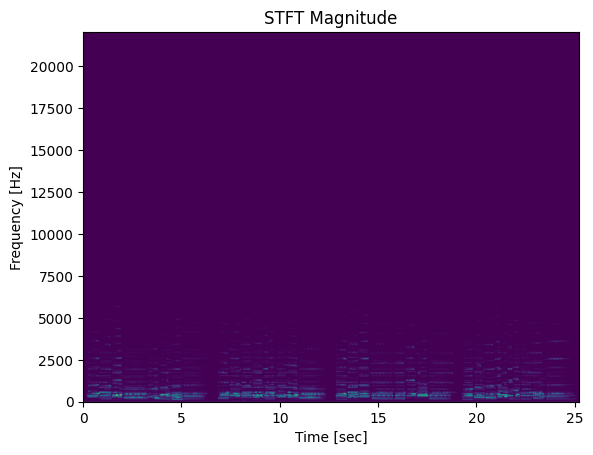

In [7]:
# Exemple Application de la stft d'aprés la doc de scipy
# POur determiner la bonne taille de la fenetre nperseg, on peut essayer plusieurs valeurs et observer le resultat
f, t, Zxx = scipy.signal.stft(x, fs=fs, nperseg=1024)
amp = np.max(np.abs(Zxx))
plt.pcolormesh(t, f, np.abs(Zxx), vmin=0, vmax=amp, shading='gouraud')
plt.title('STFT Magnitude')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')
plt.show()

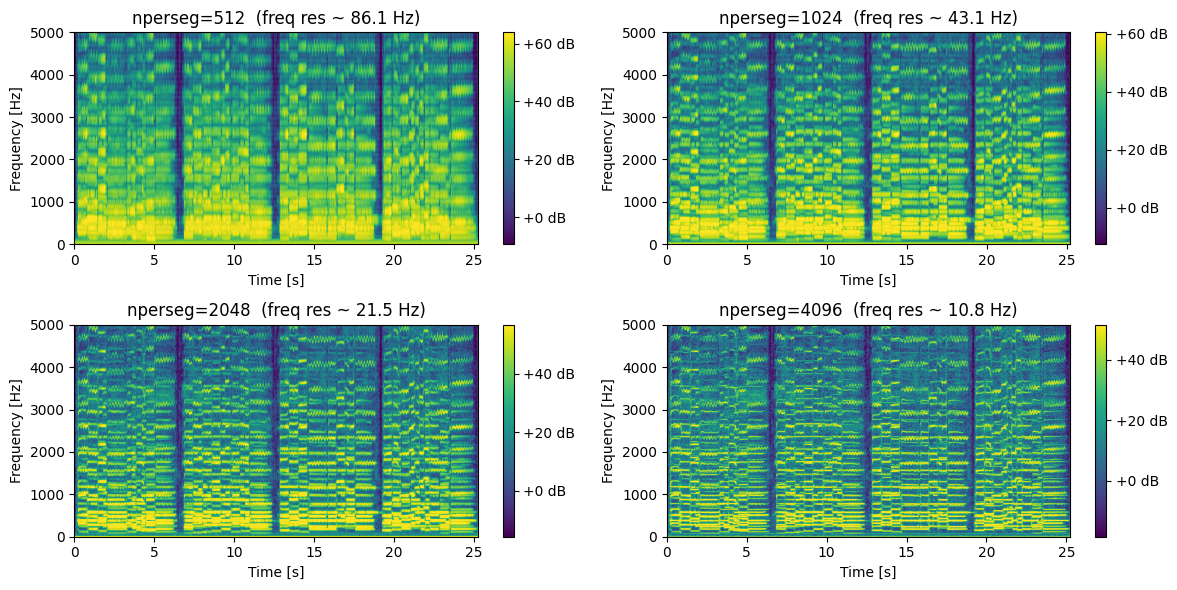

In [8]:
# teste de plusieurs valeurs de nperseg

candidates = [512, 1024, 2048, 4096]
ncol = 2
nrow = int(np.ceil(len(candidates)/ncol))

plt.figure(figsize=(12, 3*nrow))

for i, nper in enumerate(candidates, 1):
    f, t, Zxx = scipy.signal.stft(
        x, fs=fs, nperseg=nper, 
        window='hann',
        nfft=max(4096, nper),  
        noverlap=int(0.75*nper)
    )

    S_db = 20*np.log10(np.abs(Zxx) + 1e-6)

    # limiter affichage à 0–5000 Hz 
    f_lim = 5000
    idx = f <= f_lim

    ax = plt.subplot(nrow, ncol, i)
    pcm = ax.pcolormesh(t, f[idx], S_db[idx], shading='gouraud')

    ax.set_title(f'nperseg={nper}  (freq res ~ {fs/nper:.1f} Hz)')
    ax.set_ylabel('Frequency [Hz]')
    ax.set_xlabel('Time [s]')
    ax.set_ylim(0, f_lim)   # focus zone utile

    # scale dynamique automatique
    vmin, vmax = np.percentile(S_db, [5, 99])
    pcm.set_clim(vmin, vmax)

    plt.colorbar(pcm, ax=ax, format='%+2.0f dB')

plt.tight_layout()
plt.show()



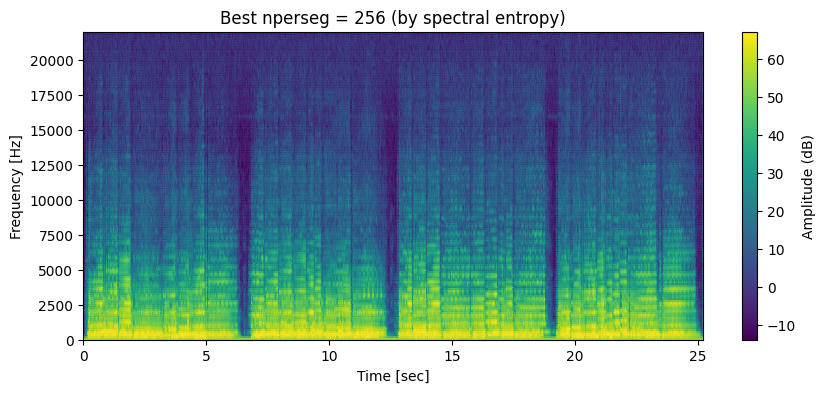

In [9]:
# Choix de nperseg par entropie spectrale

candidates = [256, 512, 1024, 2048, 4096]

def spectral_entropy(S):
    S_norm = S / (np.sum(S, axis=0, keepdims=True) + 1e-12)
    ent = -np.sum(S_norm * np.log(S_norm + 1e-12), axis=0)
    return np.mean(ent)

best = None
best_ent = 1e9
for nper in candidates:
    f, t, Zxx = scipy.signal.stft(x, fs=fs, nperseg=nper, window='hann', noverlap=int(0.75*nper))
    S = np.abs(Zxx)
    ent = spectral_entropy(S) # entropie
    if ent < best_ent:
        best_ent = ent
        best = (nper, f, t, Zxx)

nper_best, f_best, t_best, Zxx_best = best
S_db = 20*np.log10(np.abs(Zxx_best) + 1e-6)
vmax = np.percentile(S_db, 99)
vmin = np.percentile(S_db, 1)

plt.figure(figsize=(10,4))
plt.pcolormesh(t_best, f_best, S_db, vmin=vmin, vmax=vmax, shading='gouraud')
plt.title(f'Best nperseg = {nper_best} (by spectral entropy)')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')
plt.colorbar(label='Amplitude (dB)')
plt.show()


In [14]:
# NMF
model = NMF(n_components=3, max_iter=2000, beta_loss=2)
amp = np.abs(Zxx_best)
W = model.fit_transform(amp)
H = model.components_

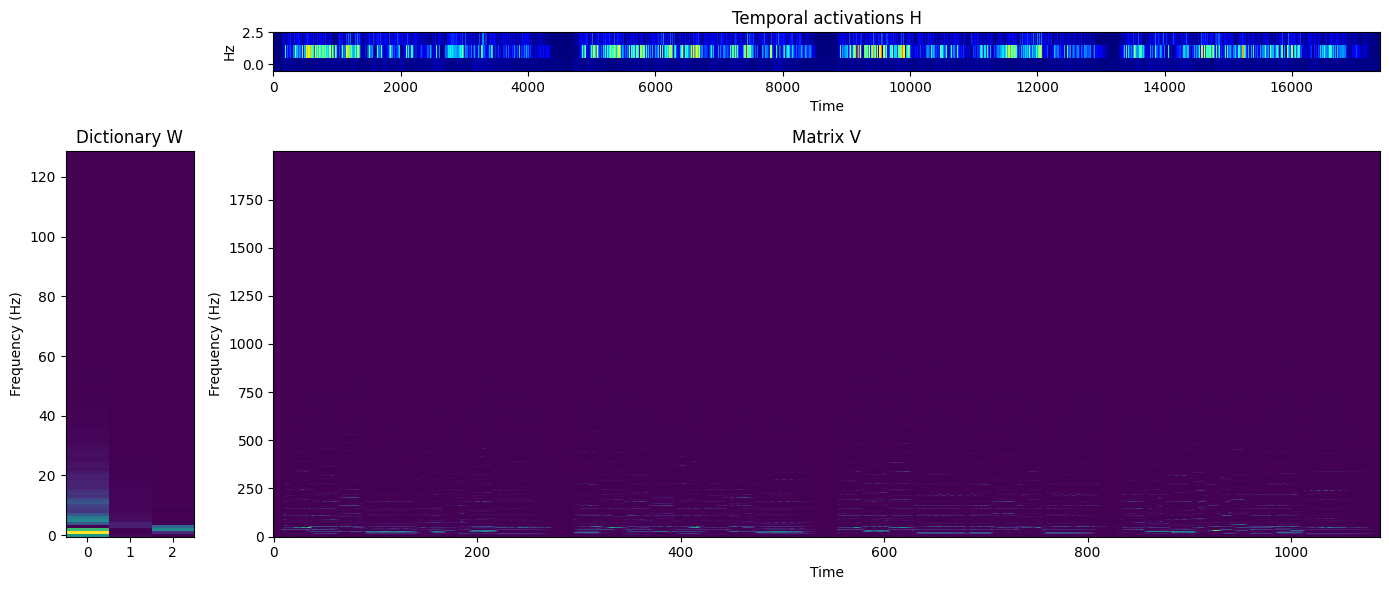

In [16]:
# --- FIGURE ---
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 4, 4], height_ratios=[1, 10])

# -----------------------
#     MATRICE H (en haut)
# -----------------------
ax_H = fig.add_subplot(gs[0, 1:])
imH = ax_H.imshow(H, aspect='auto', origin='lower',interpolation='nearest', cmap='jet')
ax_H.set_title("Temporal activations H")
ax_H.set_ylabel("Hz")
ax_H.set_xlabel("Time")

# -----------------------
#       MATRICE W (gauche)
# -----------------------
ax_W = fig.add_subplot(gs[1, 0])
imW = ax_W.imshow(W[:1500],aspect='auto', origin='lower', interpolation='nearest')
ax_W.set_title("Dictionary W")
ax_W.set_ylabel("Frequency (Hz)")

# -----------------------
# MATRICE V (spectrogramme)
# -----------------------
ax_V = fig.add_subplot(gs[1, 1:])
imV = ax_V.imshow(np.abs(Zxx)[:2000], aspect='auto', origin='lower', interpolation='nearest')
ax_V.set_title("Matrix V")
ax_V.set_xlabel("Time")
ax_V.set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()